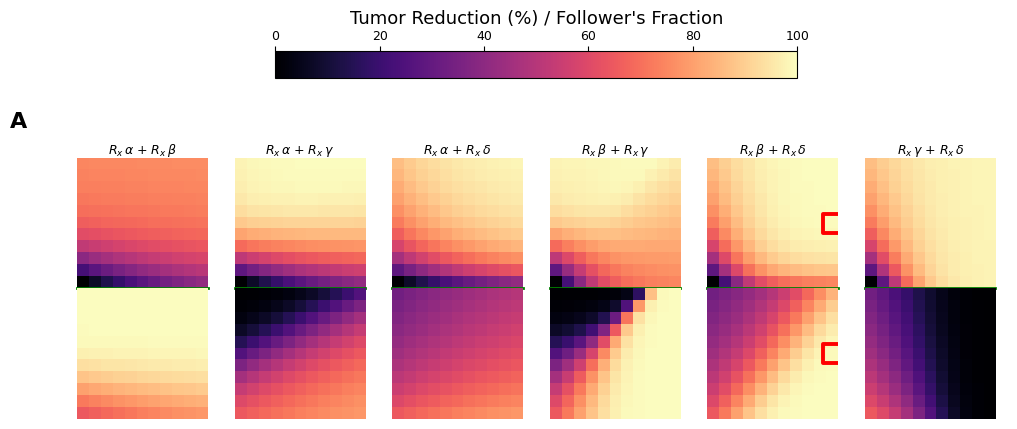

Saved: sn1.pdf


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import odeint
from itertools import combinations

# If running in Colab, keep this; otherwise comment it out
from google.colab import files

# ----------------------------
# Model: correct simultaneous hits
# ----------------------------
def apply_hits(params, c_alpha=0.0, c_beta=0.0, c_gamma=0.0, c_delta=0.0):
    alpha = params["alpha"] * (1.0 - c_alpha)
    beta  = params["beta"]  * (1.0 - c_beta)
    gamma = params["gamma"] * (1.0 - c_gamma)
    delta = params["delta"] * (1.0 - c_delta)
    return alpha, beta, gamma, delta

def parse_scenario_pair(sc1, sc2, c1, c2):
    """
    Each drug hits its target; if both hit same target, take max dose.
    sc1 uses c1, sc2 uses c2.
    """
    c_alpha = c_beta = c_gamma = c_delta = 0.0

    if sc1 == "LL": c_alpha = float(c1)
    if sc1 == "LF": c_beta  = float(c1)
    if sc1 == "FL": c_gamma = float(c1)
    if sc1 == "FF": c_delta = float(c1)

    if sc2 == "LL": c_alpha = max(c_alpha, float(c2))
    if sc2 == "LF": c_beta  = max(c_beta,  float(c2))
    if sc2 == "FL": c_gamma = max(c_gamma, float(c2))
    if sc2 == "FF": c_delta = max(c_delta, float(c2))

    return c_alpha, c_beta, c_gamma, c_delta

def f_L(x, params, c_alpha=0.0, c_beta=0.0, c_gamma=0.0, c_delta=0.0):
    alpha_eff, beta_eff, _, _ = apply_hits(params, c_alpha, c_beta, c_gamma, c_delta)
    return alpha_eff * x + beta_eff * (1.0 - x)

def f_F(x, params, c_alpha=0.0, c_beta=0.0, c_gamma=0.0, c_delta=0.0):
    _, _, gamma_eff, delta_eff = apply_hits(params, c_alpha, c_beta, c_gamma, c_delta)
    return gamma_eff * x + delta_eff * (1.0 - x)

def replicator_equations(y, t, params, c1, c2, sc1, sc2):
    N, x = y
    x = float(np.clip(x, 1e-12, 1.0 - 1e-12))

    c_alpha, c_beta, c_gamma, c_delta = parse_scenario_pair(sc1, sc2, c1, c2)
    fL = f_L(x, params, c_alpha, c_beta, c_gamma, c_delta)
    fF = f_F(x, params, c_alpha, c_beta, c_gamma, c_delta)

    dN = ((fL - fF) * N * x + fF * N)
    dx = (fL - fF) * x * (1.0 - x)
    return [dN, dx]

def simulate_final(params, c1, c2, sc1, sc2, t, N0, x0):
    sol = odeint(
        replicator_equations, [float(N0), float(x0)], t,
        args=(params, float(c1), float(c2), sc1, sc2),
        mxstep=20000
    )
    N_end = float(sol[-1, 0])
    x_end = float(sol[-1, 1])
    return N_end, x_end

# ----------------------------
# Grids + objective J = R/100 - x
# ----------------------------
def compute_grids_with_J(params, drug_costs, t, N0, x0, sc1, sc2):
    n = len(drug_costs)

    N_base, _ = simulate_final(params, 0.0, 0.0, "no_drug", "no_drug", t, N0, x0)

    red  = np.zeros((n, n), float)  # reduction (%)
    xfin = np.zeros((n, n), float)  # x(T)
    Jmat = np.zeros((n, n), float)  # objective

    for i, c1 in enumerate(drug_costs):
        for j, c2 in enumerate(drug_costs):
            N_t, x_t = simulate_final(params, c1, c2, sc1, sc2, t, N0, x0)

            reduction = (N_base - N_t) / N_base * 100.0
            reduction = np.clip(reduction, 0.0, 100.0)

            # display coordinates: higher c2 at top
            jj = n - 1 - j
            ii = i

            x_t = float(np.clip(x_t, 0.0, 1.0))
            red[jj, ii]  = reduction
            xfin[jj, ii] = x_t
            Jmat[jj, ii] = (reduction / 100.0) - x_t

    return red, xfin, Jmat

def find_global_best(params, drug_costs, t, N0, x0, scenario_pairs):
    best = {"J": -np.inf, "pair_idx": None, "i": None, "j": None}
    for pidx, (s1, s2) in enumerate(scenario_pairs):
        _, _, Jmat = compute_grids_with_J(params, drug_costs, t, N0, x0, s1, s2)
        flat = np.nanargmax(Jmat)
        j, i = np.unravel_index(flat, Jmat.shape)
        if float(Jmat[j, i]) > best["J"]:
            best.update({"J": float(Jmat[j, i]), "pair_idx": pidx, "i": int(i), "j": int(j)})
    return best

# ----------------------------
# Plot ONE GAME: 1 row x 6 composites
# ----------------------------
def plot_one_game_A(params, drug_costs, t, N0, x0, savepath="sn1.pdf"):
    # High-quality figure settings
    plt.rcParams.update({
        "font.size": 9,
        "axes.titlesize": 9,
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
    })

    pretty = {
        "LL": r"$R_x\,\alpha$",
        "LF": r"$R_x\,\beta$",
        "FL": r"$R_x\,\gamma$",
        "FF": r"$R_x\,\delta$"
    }

    scenarios = ["LL", "LF", "FL", "FF"]
    scenario_pairs = list(combinations(scenarios, 2))  # 6 pairs
    best = find_global_best(params, drug_costs, t, N0, x0, scenario_pairs)

    # Bigger panels, tighter horizontal spacing
    fig, axes = plt.subplots(1, 6, figsize=(10, 4.2), constrained_layout=True)
    fig.set_constrained_layout_pads(w_pad=0.01, h_pad=0.01, wspace=0.000001, hspace=0.005)

    # Colormaps / scales
    vmin_red, vmax_red = 0, 100
    vmin_x,   vmax_x   = 0, 1
    cmap_red = "magma"
    cmap_x   = "magma_r"

    im_red_ref = None  # reference for tumor reduction colorbar

    for col, (s1, s2) in enumerate(scenario_pairs):
        ax_outer = axes[col]
        ax_outer.set_xticks([])
        ax_outer.set_yticks([])
        for sp in ax_outer.spines.values():
            sp.set_visible(False)

        # two inset axes that touch (no white gap)
        ax_top = ax_outer.inset_axes([0.0, 0.5, 1.0, 0.5])
        ax_bot = ax_outer.inset_axes([0.0, 0.0, 1.0, 0.5])

        red, xfin, _ = compute_grids_with_J(params, drug_costs, t, N0, x0, s1, s2)

        im_top = ax_top.imshow(
            red, cmap=cmap_red, vmin=vmin_red, vmax=vmax_red,
            origin="upper", aspect="equal", interpolation="nearest"
        )
        im_red_ref = im_top

        ax_bot.imshow(
            xfin, cmap=cmap_x, vmin=vmin_x, vmax=vmax_x,
            origin="upper", aspect="equal", interpolation="nearest"
        )

        # clean axes
        for ax in (ax_top, ax_bot):
            ax.set_xticks([])
            ax.set_yticks([])
            for sp in ax.spines.values():
                sp.set_visible(False)

        # green separator line
        ax_top.spines["bottom"].set_visible(True)
        ax_top.spines["bottom"].set_color("green")
        ax_top.spines["bottom"].set_linewidth(2.0)

        # title
        ax_top.set_title(f"{pretty[s1]} + {pretty[s2]}", pad=2)

        # highlight best cell for best pair
        if col == best["pair_idx"]:
            i_opt, j_opt = best["i"], best["j"]
            for ax in (ax_top, ax_bot):
                ax.scatter(
                    [i_opt], [j_opt],
                    marker="s", s=180,
                    facecolors="none", edgecolors="red",
                    linewidths=2.8, zorder=10
                )

    # Panel letter only
    axes[0].text(-0.35, 1.18, "A", transform=axes[0].transAxes,
                 fontsize=16, fontweight="bold", va="top", ha="left")

    # ---- ONE horizontal colorbar for tumor reduction ONLY (top) ----
    cbar = fig.colorbar(
        im_red_ref,
        ax=axes,
        orientation="horizontal",
        location="top",
        fraction=0.1,
        pad=0.1
    )
    cbar.set_label("Tumor Reduction (%) / Follower's Fraction", fontsize=13)

    # Save as vector PDF (best for PNAS), high dpi not needed for vector, but keep bbox tight
    fig.savefig(savepath, bbox_inches="tight")
    plt.show()
    print(f"Saved: {savepath}")

# ----------------------------
# RUN: First game only (A)\
# ----------------------------
if __name__ == "__main__":
    drug_costs = np.linspace(0, 1.0, 11)
    t = np.linspace(0, 15, 500)
    N0 = 1e5
    x0 = 0.5

    #
    params = {"alpha": 0.4, "delta": 0.6, "gamma": 0.8, "beta": 0.8}

    plot_one_game_A(params, drug_costs, t, N0, x0, savepath="sn1.pdf")

    # Download in Colab
    files.download("sn1.pdf")